<a href="https://colab.research.google.com/github/haydencase0/MachineLearning/blob/main/Team4Module2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import polars as pl
import polars.selectors as cs
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from plotnine import ggplot, aes, geom_col, theme_minimal, labs
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [ ]:
data = pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv", infer_schema_length=10000)
data

age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
i64,str,str,str,str,str,str,str,str,str,i64,i64,i64,str,f64,f64,f64,f64,f64,str
56,"""housemaid""","""married""","""basic.4y""","""no""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
57,"""services""","""married""","""high.school""","""unknown""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
37,"""services""","""married""","""high.school""","""no""","""yes""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
40,"""admin.""","""married""","""basic.6y""","""no""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
56,"""services""","""married""","""high.school""","""no""","""no""","""yes""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
73,"""retired""","""married""","""professional.course""","""no""","""yes""","""no""","""cellular""","""nov""","""fri""",1,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""yes"""
46,"""blue-collar""","""married""","""professional.course""","""no""","""no""","""no""","""cellular""","""nov""","""fri""",1,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""no"""
56,"""retired""","""married""","""university.degree""","""no""","""yes""","""no""","""cellular""","""nov""","""fri""",2,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""no"""


identifying those customers most likely to subscribe to a term deposit

find any actionable patterns in our results.
Should we only call single people on Saturdays?
Does it make sense to call students at all?

does contacting people too frequently for these marketing campaigns have an adverse affect on the outcome?

there are a bunch of social and economic indicators in the data.
We should be careful about how we consider these. We may want to see separate models for times when, for example, the consumer confidence index is high compared to when it is low.

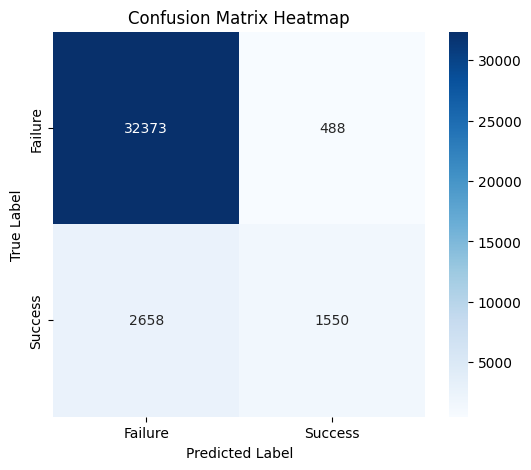

In [ ]:
features = ['age', 'job',	'marital',	'education',	'default',	'housing',
            'loan',	'contact',	'month',	'day_of_week',	'campaign',
            'pdays',	'previous',	'emp.var.rate',	'cons.price.idx',
            'cons.conf.idx',	'euribor3m', 'nr.employed', 'poutcome']
X = data.select(features).to_dummies(features, drop_first=True)
y = data.select(pl.col('y'))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30)

clf = DecisionTreeClassifier(max_depth=15)

clf.fit(X_train, y_train)

clf.score(X_test, y_test)

y_pred = clf.predict(X)
clean = data.with_columns(pl.Series(name="y", values=y_pred.tolist()))

cm = confusion_matrix(y, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Failure', 'Success'],
            yticklabels=['Failure', 'Success'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()

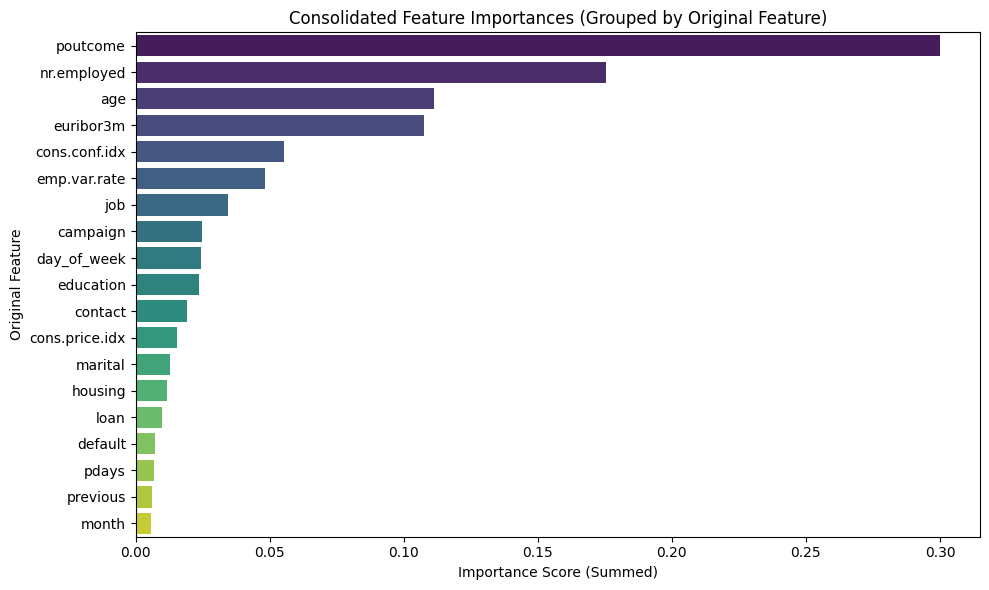

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract raw feature importances and their dummy column names
importances = clf.feature_importances_
feature_names = X.columns

# Map each dummy column back to its original parent feature
mapped_importances = []
for col_name, imp in zip(feature_names, importances):
    matched = False
    # Sort original features by length descending to match longest substring first (e.g. 'nr.employed' before 'age')
    for original_feature in sorted(features, key=len, reverse=True):
        if col_name.startswith(original_feature):
            mapped_importances.append({'Original_Feature': original_feature, 'Importance': imp})
            matched = True
            break
    if not matched:
        mapped_importances.append({'Original_Feature': col_name, 'Importance': imp})

# Aggregate importances by the original feature names
grouped_df = (pldf := pl.DataFrame(mapped_importances))
summary_df = (
    grouped_df
    .group_by("Original_Feature")
    .agg(pl.col("Importance").sum())
    .sort("Importance", descending=True)
    .to_pandas()
)

# Plot the aggregated feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=summary_df, x='Importance', y='Original_Feature', hue='Original_Feature', legend=False, palette='viridis')
plt.title('Consolidated Feature Importances (Grouped by Original Feature)')
plt.xlabel('Importance Score (Summed)')
plt.ylabel('Original Feature')
plt.tight_layout()
plt.show()

Top 8 Features to Keep: ['poutcome', 'nr.employed', 'age', 'euribor3m', 'cons.conf.idx', 'emp.var.rate', 'job', 'campaign']
Reduced feature space from 575 to 487 columns.
Retrained Model Accuracy (Top 8 features only): 0.8934


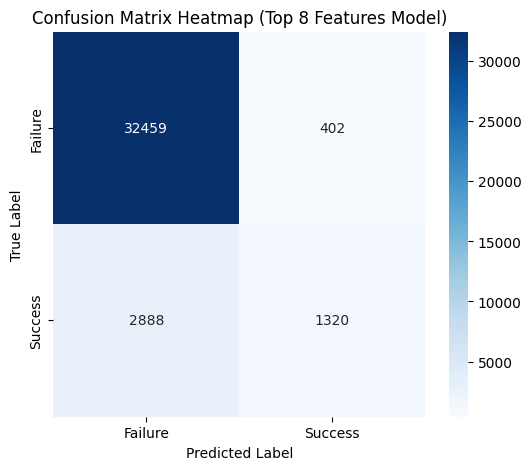

In [ ]:
# 1. Get the names of the top 8 consolidated features
top_8_features = summary_df['Original_Feature'].head(8).tolist()
print("Top 8 Features to Keep:", top_8_features)

# 2. Filter X to keep only dummy columns belonging to these top 8 features
keep_cols = []
for col_name in X.columns:
    for f in top_8_features:
        # Match dummy columns (e.g., 'job_retired' matches parent 'job')
        if col_name == f or col_name.startswith(f + "_"):
            keep_cols.append(col_name)
            break

X_top8 = X.select(keep_cols)
print(f"Reduced feature space from {X.shape[1]} to {X_top8.shape[1]} columns.")

# 3. Split the newly filtered dataset
X_train8, X_test8, y_train8, y_test8 = train_test_split(X_top8, y, test_size=0.30, random_state=42)

# 4. Retrain the classifier using only the top 8 features
clf_top8 = DecisionTreeClassifier(max_depth=15, random_state=42)
clf_top8.fit(X_train8, y_train8)

# 5. Evaluate and display the new accuracy
accuracy = clf_top8.score(X_test8, y_test8)
print(f"Retrained Model Accuracy (Top 8 features only): {accuracy:.4f}")

# Predict using the newly trained 8-feature model on the full reduced dataset
y_pred_top8 = clf_top8.predict(X_top8)

# Calculate confusion matrix with the new predictions
cm = confusion_matrix(y, y_pred_top8)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Failure', 'Success'],
            yticklabels=['Failure', 'Success'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap (Top 8 Features Model)')
plt.show()

In [ ]:
test = pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank_holdout_test.csv")

# 1. Apply dummies to the test set using the same features
X_test_dummies = test.select(features).to_dummies(features, drop_first=True)

# 2. Align test columns with the expected feature space of the top 8 model (X_top8)
# Add missing columns with 0s
missing_cols = [col for col in X_top8.columns if col not in X_test_dummies.columns]
if missing_cols:
    X_test_dummies = X_test_dummies.with_columns([
        pl.lit(0).alias(col) for col in missing_cols
    ])

# Keep and order only the columns that were present in X_top8
X_test_aligned = X_test_dummies.select(X_top8.columns)

print(f"Aligned test set feature dimensions: {X_test_aligned.shape}")

Aligned test set feature dimensions: (4119, 487)


In [ ]:
test.head(10)

age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
i64,str,str,str,str,str,str,str,str,str,i64,i64,i64,str,f64,f64,f64,f64,f64
26,"""blue-collar""","""married""","""basic.9y""","""unknown""","""yes""","""no""","""cellular""","""jul""","""tue""",2,999,0,"""nonexistent""",1.4,93.918,-42.7,4.962,5228.1
33,"""admin.""","""married""","""high.school""","""no""","""yes""","""no""","""cellular""","""may""","""tue""",1,999,0,"""nonexistent""",-1.8,92.893,-46.2,1.344,5099.1
45,"""admin.""","""divorced""","""university.degree""","""no""","""no""","""yes""","""cellular""","""jun""","""wed""",1,3,2,"""success""",-1.7,94.055,-39.8,0.739,4991.6
37,"""admin.""","""divorced""","""high.school""","""no""","""yes""","""no""","""telephone""","""jun""","""fri""",12,999,0,"""nonexistent""",1.4,94.465,-41.8,4.959,5228.1
34,"""admin.""","""single""","""high.school""","""no""","""no""","""no""","""cellular""","""nov""","""wed""",1,999,0,"""nonexistent""",-0.1,93.2,-42.0,4.12,5195.8
60,"""technician""","""married""","""basic.4y""","""no""","""yes""","""no""","""cellular""","""oct""","""tue""",2,6,1,"""success""",-3.4,92.431,-26.9,0.737,5017.5
33,"""management""","""single""","""university.degree""","""no""","""yes""","""yes""","""telephone""","""may""","""fri""",2,999,0,"""nonexistent""",1.1,93.994,-36.4,4.855,5191.0
31,"""admin.""","""single""","""university.degree""","""no""","""no""","""yes""","""cellular""","""aug""","""wed""",1,999,0,"""nonexistent""",1.4,93.444,-36.1,4.967,5228.1
48,"""blue-collar""","""married""","""basic.9y""","""no""","""yes""","""yes""","""cellular""","""may""","""tue""",4,999,1,"""failure""",-1.8,92.893,-46.2,1.291,5099.1


In [ ]:
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

          no       0.92      0.99      0.95     32861
         yes       0.76      0.37      0.50      4208

    accuracy                           0.92     37069
   macro avg       0.84      0.68      0.72     37069
weighted avg       0.91      0.92      0.90     37069



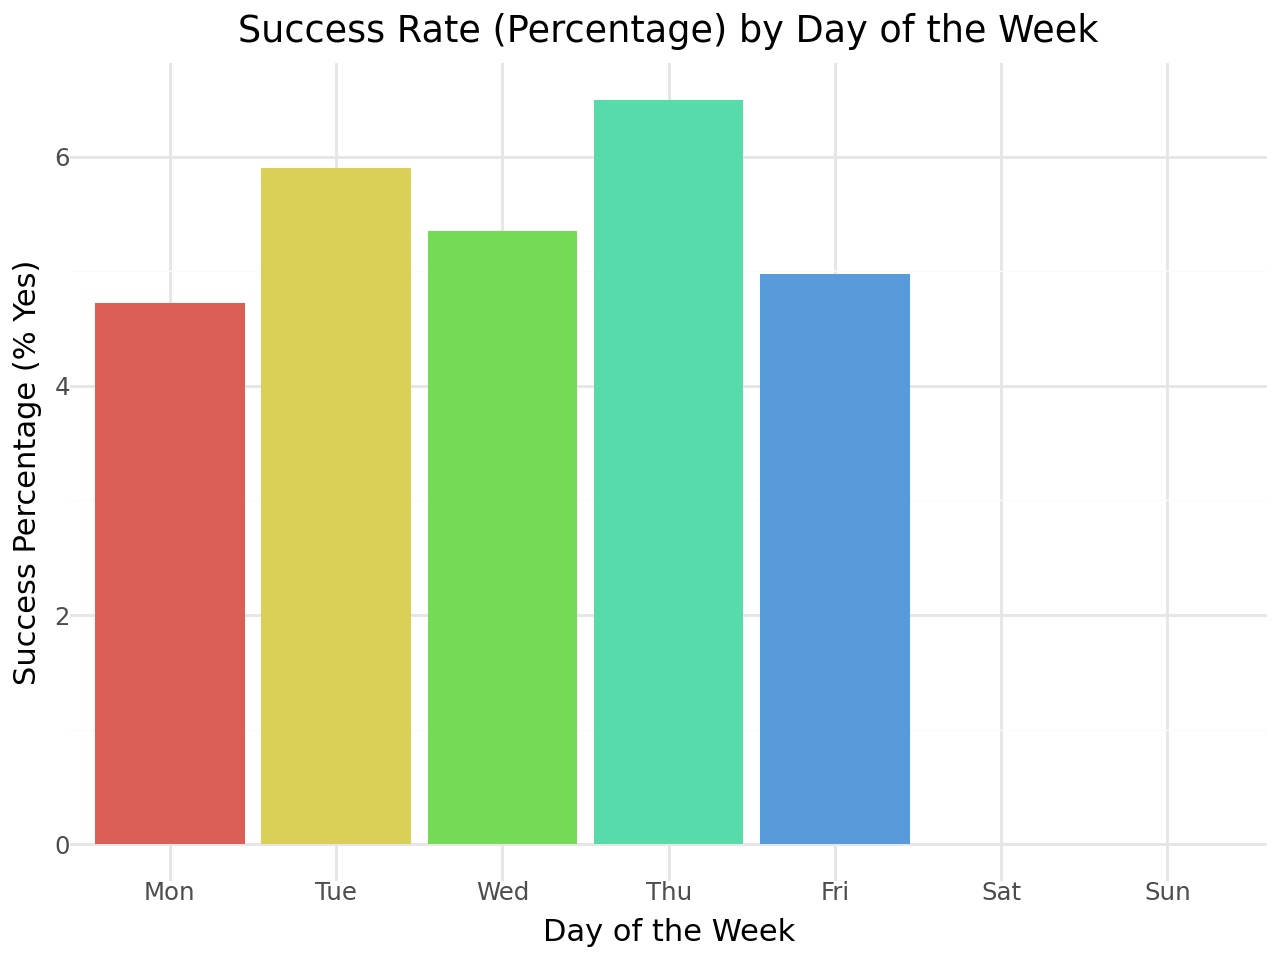

In [ ]:
day_mapping = {
    'mon': 'Mon',
    'tue': 'Tue',
    'wed': 'Wed',
    'thu': 'Thu',
    'fri': 'Fri',
    'sat': 'Sat',
    'sun': 'Sun'
}

# Create a template DataFrame to ensure all days are represented
all_days = pl.DataFrame({"day_of_week": ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']})

# Calculate both total calls and successes per day to get percentages
day_stats = (
    clean
    .group_by("day_of_week")
    .agg([
        pl.len().alias("total_calls"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("success_count")
    ])
)

# Join, compute percentages, and clean up for plotting
success_percentages = (
    all_days
    .join(day_stats, on="day_of_week", how="left")
    .with_columns([
        pl.col("total_calls").fill_null(0),
        pl.col("success_count").fill_null(0)
    ])
    .with_columns(
        pl.when(pl.col("total_calls") > 0)
        .then((pl.col("success_count") / pl.col("total_calls")) * 100)
        .otherwise(0.0)
        .alias("success_percentage")
    )
    .with_columns(
        pl.col("day_of_week")
        .replace_strict(day_mapping)
        .cast(pl.Categorical(ordering="lexical"))
        .alias("day_name")
    )
)

# Generate the plot representing percentage
graph = (
    ggplot(success_percentages, aes(x='day_name', y='success_percentage', fill='day_name'))
    + geom_col(show_legend=False)
    + theme_minimal()
    + labs(
        title="Success Rate (Percentage) by Day of the Week",
        x="Day of the Week",
        y="Success Percentage (% Yes)"
    )
)

graph

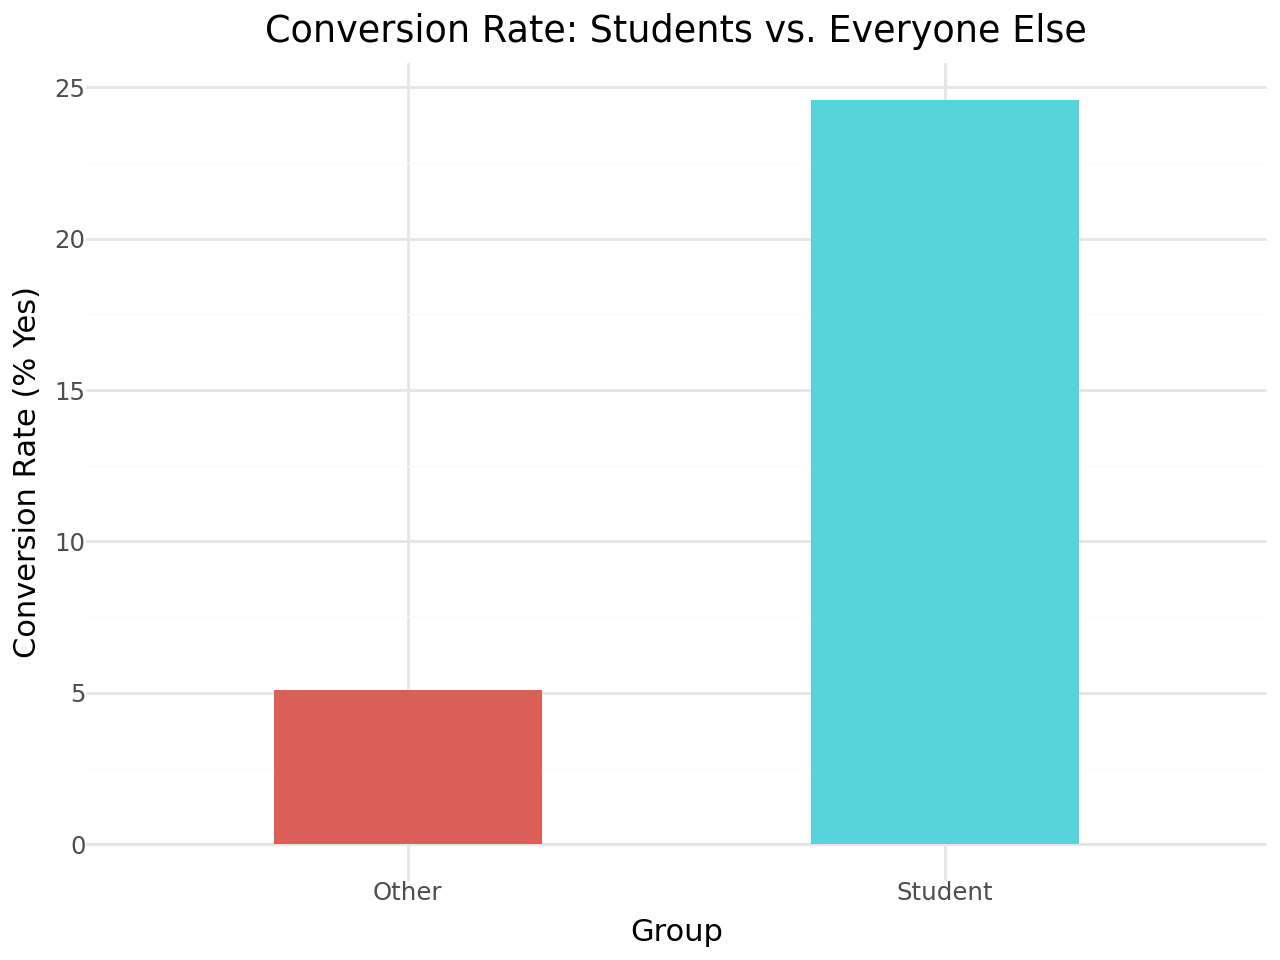

In [ ]:
conversion_rates = (
    clean
    .with_columns(
        pl.when(pl.col("job") == "student")
        .then(pl.lit("Student"))
        .otherwise(pl.lit("Other"))
        .cast(pl.Categorical(ordering="lexical"))
        .alias("group")
    )
    .group_by("group")
    .agg([
        pl.len().alias("total"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("yes_count")
    ])
    .with_columns(
        (pl.col("yes_count") / pl.col("total") * 100).alias("conversion_rate")
    )
)

(
    ggplot(conversion_rates, aes(x='group', y='conversion_rate', fill='group'))
    + geom_col(show_legend=False, width=0.5)
    + theme_minimal()
    + labs(
        title="Conversion Rate: Students vs. Everyone Else",
        x="Group",
        y="Conversion Rate (% Yes)"
    )
)

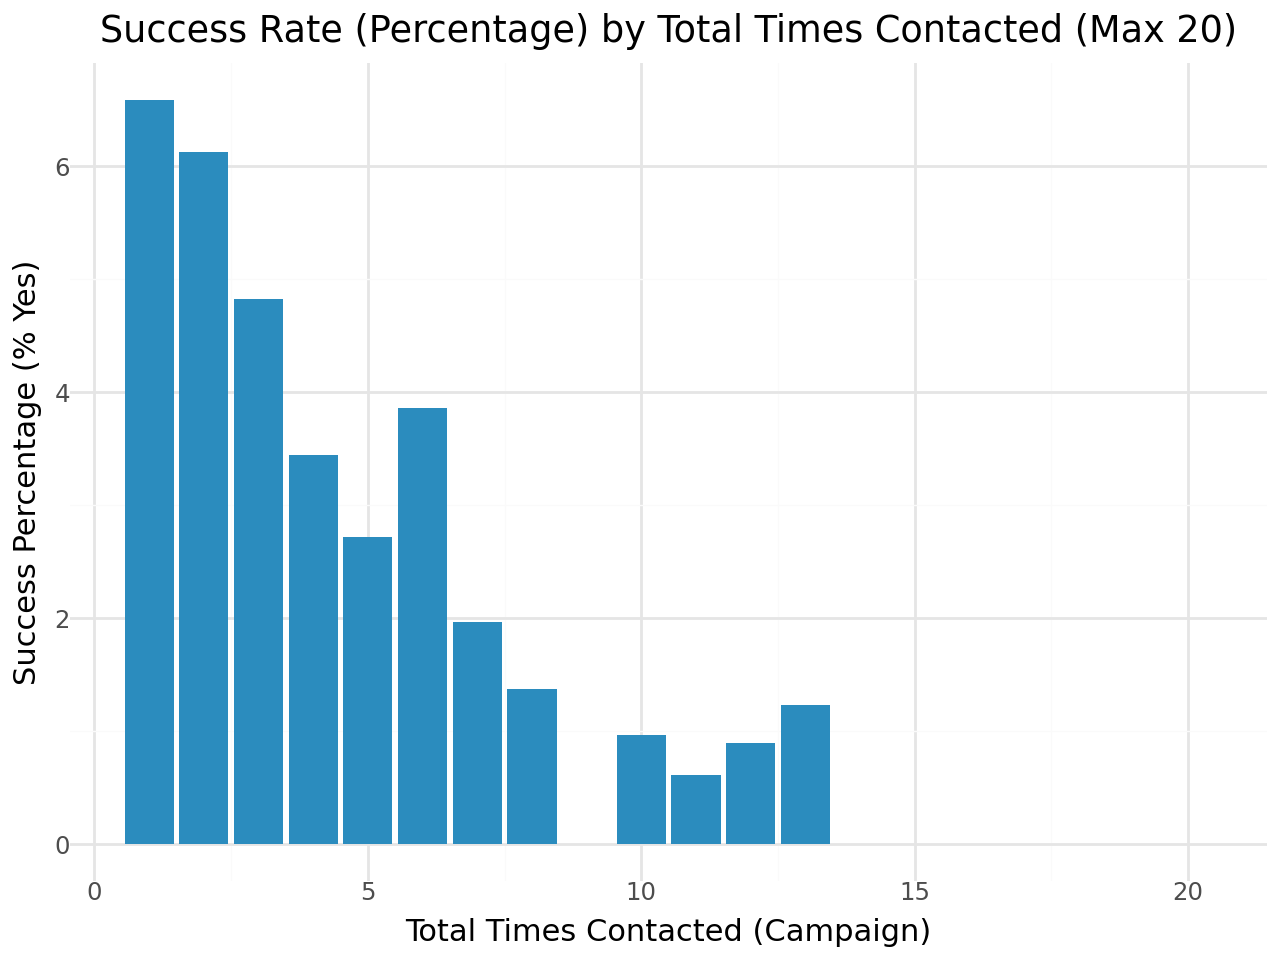

In [ ]:
contact_stats = (
    clean
    .filter(pl.col("campaign") <= 20)
    .group_by("campaign")
    .agg([
        pl.len().alias("total_calls"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("success_count")
    ])
    .with_columns(
        ((pl.col("success_count") / pl.col("total_calls")) * 100).alias("success_percentage")
    )
    .sort("campaign")
)

(
    ggplot(contact_stats, aes(x='campaign', y='success_percentage'))
    + geom_col(fill='#2b8cbe')
    + theme_minimal()
    + labs(
        title="Success Rate (Percentage) by Total Times Contacted (Max 20)",
        x="Total Times Contacted (Campaign)",
        y="Success Percentage (% Yes)"
    )
)

In [ ]:
# 1. Predict using the trained top 8 model on the properly encoded and aligned test set
predictions = clf_top8.predict(X_test_aligned)

# 2. Convert predictions to a Polars DataFrame and map/cast 'yes'/'no' to 1/0
my_predictions = pl.DataFrame(predictions, schema=['y']).with_columns([
    pl.when(pl.col('y') == 'yes').then(1).otherwise(0).alias('y')
])

# 3. Export predictions to the team submission file
my_predictions.write_csv("team4-module2-predictions.csv")
print("Predictions saved successfully. Output shape:", my_predictions.shape)
print(my_predictions.head(10))

Predictions saved successfully. Output shape: (4119, 1)
shape: (10, 1)
┌─────┐
│ y   │
│ --- │
│ i32 │
╞═════╡
│ 0   │
│ 0   │
│ 1   │
│ 0   │
│ 0   │
│ 1   │
│ 0   │
│ 0   │
│ 0   │
│ 0   │
└─────┘
